# Red Wine Quality — Baseline Checkpoint

Regularized regression (ridge, lasso) and a small MLP under nested cross-validation. Repository version: paths adapted for local execution; experiment logic unchanged.

## 1. Data Loading, Deduplication, and Train–Test Split

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

CSV_PATH = "data/winequality-red.csv"
SPLIT_SEED = 42
TEST_FRACTION = 0.20

# Read the uploaded CSV and detect its separator.
raw = pd.read_csv(CSV_PATH, sep=None, engine="python")

missing_rows = int(raw.isna().any(axis=1).sum())
if missing_rows:
    raise ValueError(f"Found {missing_rows} rows with missing values.")

# Remove exact duplicates before splitting.
wines = raw.drop_duplicates().reset_index(drop=True)

# Set aside 20% of the data for final evaluation.
dev_data, test_data = train_test_split(
    wines, test_size=TEST_FRACTION, random_state=SPLIT_SEED
)

dev_data = dev_data.reset_index(drop=True)
X_dev = dev_data.drop(columns="quality")
y_dev = dev_data["quality"]

print(f"Original rows: {len(raw):,}")
print(f"Missing-value rows: {missing_rows:,}")
print(f"Exact duplicates removed: {len(raw) - len(wines):,}")
print(f"Rows after deduplication: {len(wines):,}")
print(f"Input features: {X_dev.shape[1]}")
print(f"Target: {y_dev.name}")
print(f"Development rows: {len(dev_data):,}")
print(f"Held-out test rows: {len(test_data):,}")

Original rows: 1,599
Missing-value rows: 0
Exact duplicates removed: 240
Rows after deduplication: 1,359
Input features: 11
Target: quality
Development rows: 1,087
Held-out test rows: 272


## 2. Cross-Validation Setup

In [2]:
from sklearn.model_selection import KFold

N_SPLITS = 5
CV_SEEDS = (42, 43, 44, 45, 46)
PRIMARY_CV_SEED = CV_SEEDS[0]

# Create five sets of outer folds using only the development data.
outer_folds = {}
for seed in CV_SEEDS:
    outer_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)
    outer_folds[seed] = list(outer_cv.split(X_dev))

# Use this splitter for tuning within each outer training fold.
inner_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=PRIMARY_CV_SEED)

train_idx, val_idx = outer_folds[PRIMARY_CV_SEED][0]
print(f"CV seeds: {CV_SEEDS}")
print(f"Total outer folds: {sum(len(folds) for folds in outer_folds.values())}")
print(f"First outer fold: {len(train_idx)} training rows, {len(val_idx)} validation rows")

CV seeds: (42, 43, 44, 45, 46)
Total outer folds: 25
First outer fold: 869 training rows, 218 validation rows


## 3. Training-Mean Baseline


In [3]:
import numpy as np
from sklearn.metrics import mean_absolute_error

mean_scores = []

for seed, folds in outer_folds.items():
    for fold, (train_idx, val_idx) in enumerate(folds, start=1):
        y_train = y_dev.iloc[train_idx]
        y_val = y_dev.iloc[val_idx]

        # Predict every validation wine using this fold's training mean.
        predictions = np.full(len(y_val), y_train.mean())
        mae = mean_absolute_error(y_val, predictions)
        mean_scores.append({"seed": seed, "fold": fold, "mae": mae})

mean_cv_results = pd.DataFrame(mean_scores)

primary_fold_maes = mean_cv_results.loc[
    mean_cv_results["seed"] == PRIMARY_CV_SEED, "mae"
]
primary_mae = primary_fold_maes.mean()
primary_se = primary_fold_maes.std(ddof=1) / np.sqrt(len(primary_fold_maes))

repeated_mae = mean_cv_results["mae"].mean()
repeated_fold_sd = mean_cv_results["mae"].std(ddof=1)

print(f"Primary 5-fold MAE: {primary_mae:.4f} ± {primary_se:.4f} (approx. SE)")
print(f"Repeated 5-fold MAE: {repeated_mae:.4f}")
print(f"SD across the 25 folds: {repeated_fold_sd:.4f}")

Primary 5-fold MAE: 0.6916 ± 0.0192 (approx. SE)
Repeated 5-fold MAE: 0.6913
SD across the 25 folds: 0.0291


## 4. Ridge and Lasso with Nested Cross-Validation

In [4]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

linear_models = {
    "Ridge": (Ridge(), np.logspace(-3, 5, 9)),
    "Lasso": (Lasso(max_iter=20_000), np.logspace(-5, -1, 9)),
}

linear_scores = []
linear_oof = []
linear_best_alphas = {}

for model_name, (estimator, alphas) in linear_models.items():
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator),
    ])
    search = GridSearchCV(
        pipeline,
        param_grid={"model__alpha": alphas},
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        n_jobs=-1,
    )

    for seed, folds in outer_folds.items():
        for fold, (train_idx, val_idx) in enumerate(folds, start=1):
            X_train, y_train = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
            X_val, y_val = X_dev.iloc[val_idx], y_dev.iloc[val_idx]

            # Tune on the outer training data, then score on the outer fold.
            search.fit(X_train, y_train)
            predictions = search.predict(X_val)

            linear_scores.append({
                "model": model_name,
                "seed": seed,
                "fold": fold,
                "alpha": search.best_params_["model__alpha"],
                "mae": mean_absolute_error(y_val, predictions),
            })

            # Save out-of-fold predictions from the primary seed for plotting.
            if seed == PRIMARY_CV_SEED:
                linear_oof.append(pd.DataFrame({
                    "model": model_name,
                    "actual": y_val.to_numpy(),
                    "predicted": predictions,
                }))

    # Select the setting to report using CV on the full development set.
    search.fit(X_dev, y_dev)
    linear_best_alphas[model_name] = search.best_params_["model__alpha"]

linear_cv_results = pd.DataFrame(linear_scores)
linear_oof_predictions = pd.concat(linear_oof, ignore_index=True)

for model_name, scores in linear_cv_results.groupby("model", sort=False):
    primary = scores.loc[scores["seed"] == PRIMARY_CV_SEED, "mae"]
    se = primary.std(ddof=1) / np.sqrt(len(primary))

    print(model_name)
    print(f"  Selected alpha on development set: {linear_best_alphas[model_name]:.6g}")
    print(f"  Primary 5-fold MAE: {primary.mean():.4f} ± {se:.4f} (approx. SE)")
    print(f"  Repeated 5-fold MAE: {scores['mae'].mean():.4f}")
    print(f"  SD across the 25 folds: {scores['mae'].std(ddof=1):.4f}")

Ridge
  Selected alpha on development set: 10
  Primary 5-fold MAE: 0.5174 ± 0.0092 (approx. SE)
  Repeated 5-fold MAE: 0.5171
  SD across the 25 folds: 0.0221
Lasso
  Selected alpha on development set: 0.00316228
  Primary 5-fold MAE: 0.5175 ± 0.0094 (approx. SE)
  Repeated 5-fold MAE: 0.5169
  SD across the 25 folds: 0.0219


## 5. Small MLP with Nested Cross-Validation

In [5]:
from sklearn.neural_network import MLPRegressor

mlp_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", MLPRegressor(
        random_state=PRIMARY_CV_SEED,
        learning_rate_init=0.01,
        max_iter=500,
        tol=1e-3,
        n_iter_no_change=15,
    )),
])

mlp_grid = {
    "model__hidden_layer_sizes": [(8,), (16,), (32,)],
    "model__alpha": [0.01, 0.1, 1.0],
}

mlp_search = GridSearchCV(
    mlp_pipeline,
    param_grid=mlp_grid,
    scoring="neg_mean_absolute_error",
    cv=inner_cv,
    n_jobs=-1,
)

mlp_scores = []
mlp_oof = []

for seed, folds in outer_folds.items():
    for fold, (train_idx, val_idx) in enumerate(folds, start=1):
        X_train, y_train = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
        X_val, y_val = X_dev.iloc[val_idx], y_dev.iloc[val_idx]

        # Tune on the outer training data, then score on the outer validation data.
        mlp_search.fit(X_train, y_train)
        predictions = mlp_search.predict(X_val)

        mlp_scores.append({
            "model": "MLP",
            "seed": seed,
            "fold": fold,
            "mae": mean_absolute_error(y_val, predictions),
        })

        if seed == PRIMARY_CV_SEED:
            mlp_oof.append(pd.DataFrame({
                "model": "MLP",
                "actual": y_val.to_numpy(),
                "predicted": predictions,
            }))

mlp_cv_results = pd.DataFrame(mlp_scores)
mlp_oof_predictions = pd.concat(mlp_oof, ignore_index=True)

# Select the setting to report using CV on the full development set.
mlp_search.fit(X_dev, y_dev)
mlp_best_params = mlp_search.best_params_

mlp_primary = mlp_cv_results.loc[
    mlp_cv_results["seed"] == PRIMARY_CV_SEED, "mae"
]
mlp_se = mlp_primary.std(ddof=1) / np.sqrt(len(mlp_primary))

print(f"Selected width: {mlp_best_params['model__hidden_layer_sizes'][0]}")
print(f"Selected alpha: {mlp_best_params['model__alpha']}")
print(f"Primary 5-fold MAE: {mlp_primary.mean():.4f} ± {mlp_se:.4f} (approx. SE)")
print(f"Repeated 5-fold MAE: {mlp_cv_results['mae'].mean():.4f}")
print(f"SD across the 25 folds: {mlp_cv_results['mae'].std(ddof=1):.4f}")

Selected width: 32
Selected alpha: 1.0
Primary 5-fold MAE: 0.5170 ± 0.0066 (approx. SE)
Repeated 5-fold MAE: 0.5208
SD across the 25 folds: 0.0190


## 6. Predicted vs. Actual Quality

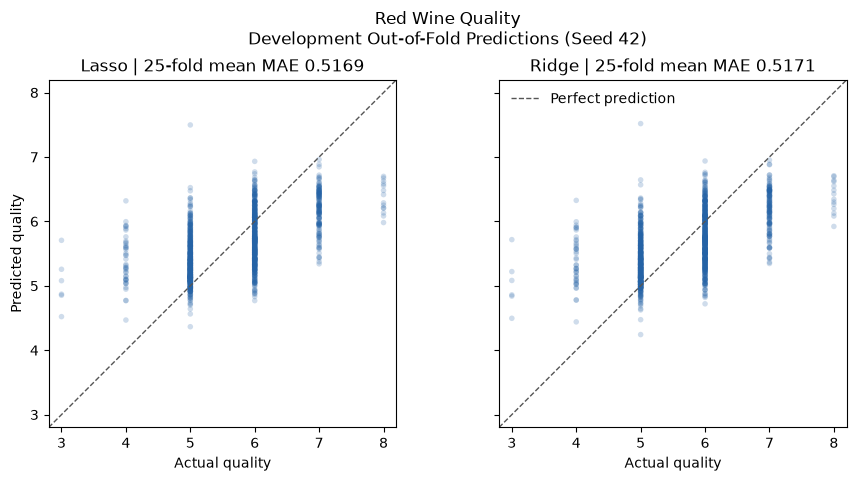

In [6]:
import matplotlib.pyplot as plt

# Rank the tuned models by mean MAE across all 25 outer folds.
model_ranking = (
    pd.concat([linear_cv_results, mlp_cv_results], ignore_index=True)
    .groupby("model")["mae"]
    .mean()
    .sort_values()
)
top_models = model_ranking.head(2).index

# Plot the out-of-fold predictions from the primary CV seed.
all_predictions = pd.concat(
    [linear_oof_predictions, mlp_oof_predictions], ignore_index=True
)
plot_data = all_predictions.loc[all_predictions["model"].isin(top_models)]

lower = plot_data[["actual", "predicted"]].min().min() - 0.2
upper = plot_data[["actual", "predicted"]].max().max() + 0.2
quality_ticks = sorted(plot_data["actual"].unique())

fig, axes = plt.subplots(
    1, 2, figsize=(9, 4.7), sharex=True, sharey=True, constrained_layout=True
)

for ax, model in zip(axes, top_models):
    points = plot_data.loc[plot_data["model"] == model]

    ax.scatter(
        points["actual"], points["predicted"],
        s=16, alpha=0.22, color="#2563A6", edgecolors="none",
    )
    ax.plot(
        [lower, upper], [lower, upper],
        linestyle="--", linewidth=1, color="#555555", label="Perfect prediction",
    )
    ax.set_title(f"{model} | 25-fold mean MAE {model_ranking[model]:.4f}")
    ax.set_xlabel("Actual quality")
    ax.set_xticks(quality_ticks)
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

axes[0].set_ylabel("Predicted quality")
axes[1].legend(loc="upper left", frameon=False)
fig.suptitle(
    f"Red Wine Quality\n"
    f"Development Out-of-Fold Predictions (Seed {PRIMARY_CV_SEED})"
)

fig.savefig("figures/baseline.png", dpi=200, bbox_inches="tight")
plt.show()